# MPC — Mixed

Analisi offline dei risultati in mpc_multimetric_th/results.

Le figure usano lo stesso set_style() della reachability: serif, formule Computer Modern, font 14 pt, curve 1.8 pt, sfondo e legenda bianchi. I dati restano quelli salvati: nessuna interpolazione BRT o simulazione MPC viene rilanciata. Le celle di esportazione salvano in grafici/output e sovrascrivono file omonimi. Nella configurazione puoi disattivare EXPORT o cambiare FORMATS e tempi dei frame.

In [3]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
if not (NOTEBOOK_DIR / "mpc_utils.py").is_file():
    if (NOTEBOOK_DIR / "grafici/mpc_utils.py").is_file():
        NOTEBOOK_DIR = NOTEBOOK_DIR / "grafici"
    else:
        raise FileNotFoundError("Apri il notebook dalla cartella grafici del repository mpc.")
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from plot_utils import set_style
from mpc_utils import (
    repository_root, load_run, run_manifest, compare_scenarios,
    plot_trajectory, plot_trajectories, plot_frames, plot_states, plot_commands,
    plot_values, plot_values_comparison, plot_hj_limits, plot_command_planes,
    plot_costs, cost_consistency, timing_statistics, plot_timings, export_collection,
)

set_style()
ROOT = repository_root(NOTEBOOK_DIR)
EXPORT = True
FORMATS = ("pdf",)  # Anche ("pdf", "eps"). EPS non conserva tutte le trasparenze.
CONTROL_FREQUENCY = 50.0
FRAME_TIMES = (5.0, 7.0, 9.0, 11.0)
VIEW_BEHIND = 10.0
VIEW_AHEAD = 25.0
HJ_STAGE = 0
HJ_SOFTENED = False  # False: vincoli originali senza slack.
PLANE_TIMES = None  # None: tre istanti nell'intervallo HJ attivo.
PER_METRIC_FIGURES = False  # True: aggiunge value e limiti per ciascuna metrica.

figures = {}

def show(name, fig):
    figures[name] = fig
    display(fig)
    plt.close(fig)

RUN_NAMES = ['mixed']
OUTPUT_GROUP = 'mixed'


## Dati e metriche effettivamente registrate

In [5]:
runs = [load_run(name, ROOT) for name in RUN_NAMES]
display(run_manifest(runs))


,run,metrics,duration_s,dt_s,steps,predictions,costs,recorded_timers
0,mixed,mixed,20.0,0.02,1000,True,True,solve_time


## Traiettoria nello spazio

Il colore rappresenta il tempo.

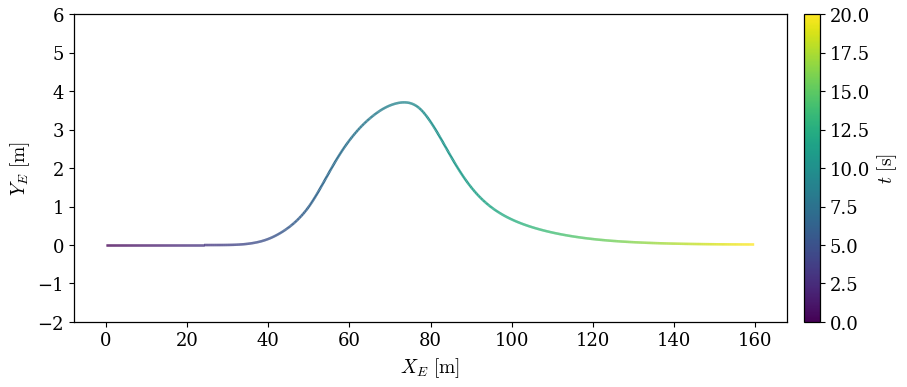

In [7]:
for run in runs:
    show(f"{run.name}_trajectory", plot_trajectory(run))


## Frame della manovra

Ego blu, human arancione e previsione MPC tratteggiata. Tempi e finestra spaziale si scelgono nella configurazione.

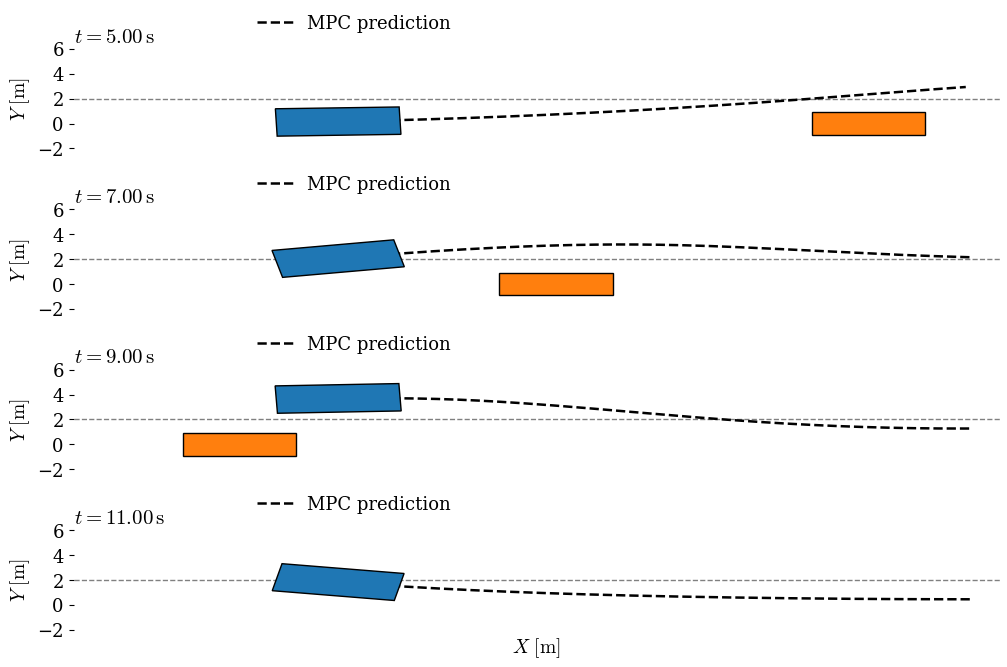

In [9]:
for run in runs:
    show(f"{run.name}_frames", plot_frames(
        run, FRAME_TIMES, behind=VIEW_BEHIND, ahead=VIEW_AHEAD
    ))


## Stati ego

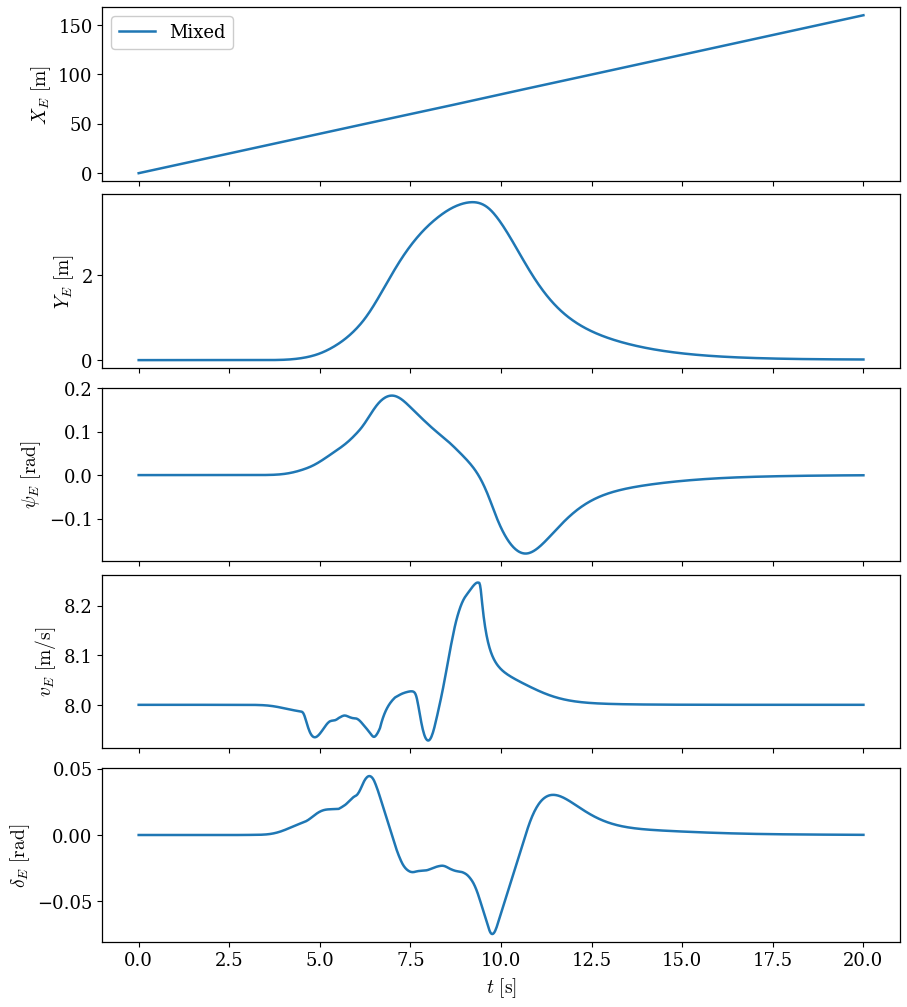

In [11]:
for run in runs:
    show(f"{run.name}_states", plot_states(run))


## Comandi ego

Ordine dei comandi salvati: steering rate, accelerazione.

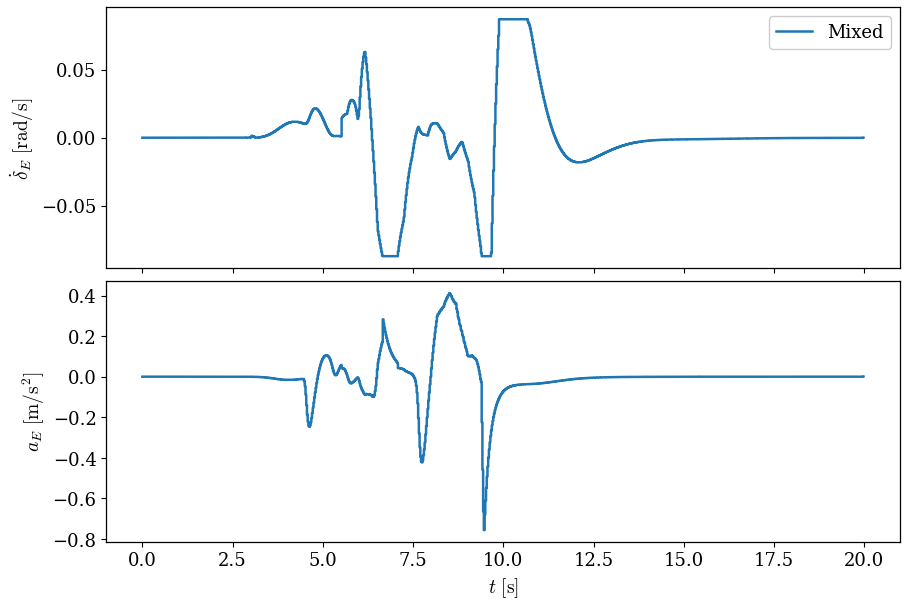

In [13]:
for run in runs:
    show(f"{run.name}_commands", plot_commands(run))


## Value function

Sono mostrati soltanto i campioni disponibili nel dominio BRT. Non vengono normalizzate le scale delle metriche.

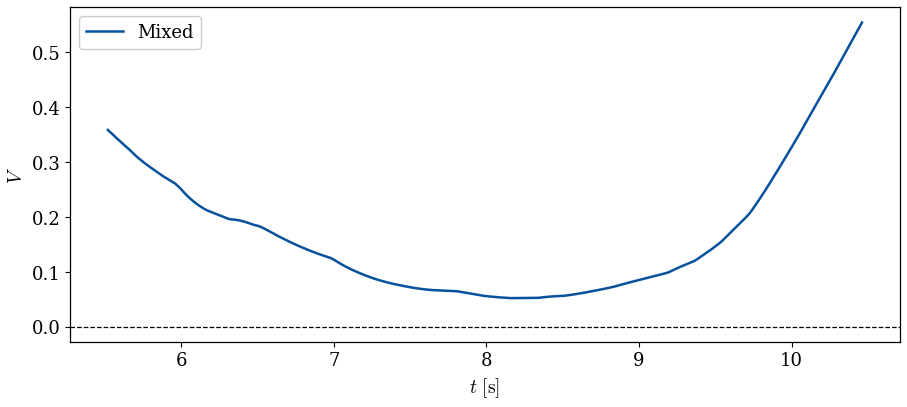

In [15]:
for run in runs:
    show(f"{run.name}_values", plot_values(run))


## Limiti HJ sui comandi

Gli intervalli sono condizionati al valore registrato dell’altro comando, allo stage HJ_STAGE. Non sono proiezioni indipendenti del piano comandi. Il verde indica l’intervallo comune; il rosso tratteggiato i limiti fisici. Con HJ_SOFTENED=False si esclude lo slack.

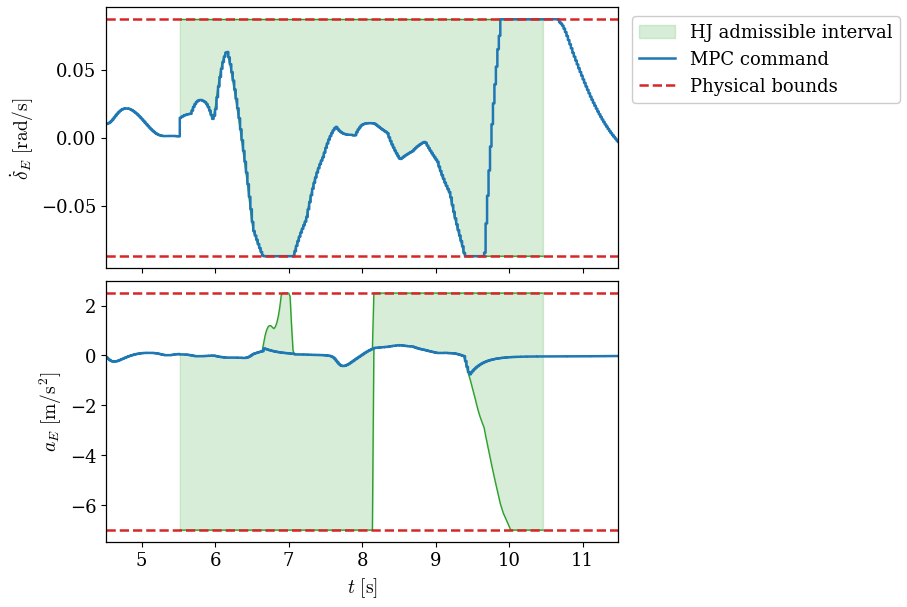

In [17]:
for run in runs:
    show(f"{run.name}_hj_limits", plot_hj_limits(
        run, stage=HJ_STAGE, softened=HJ_SOFTENED
    ))


## Piano dei comandi

Intersezione congiunta dei vincoli HJ e dei limiti fisici. La regione non comprende i vincoli di strada o la fattibilità dinamica futura.

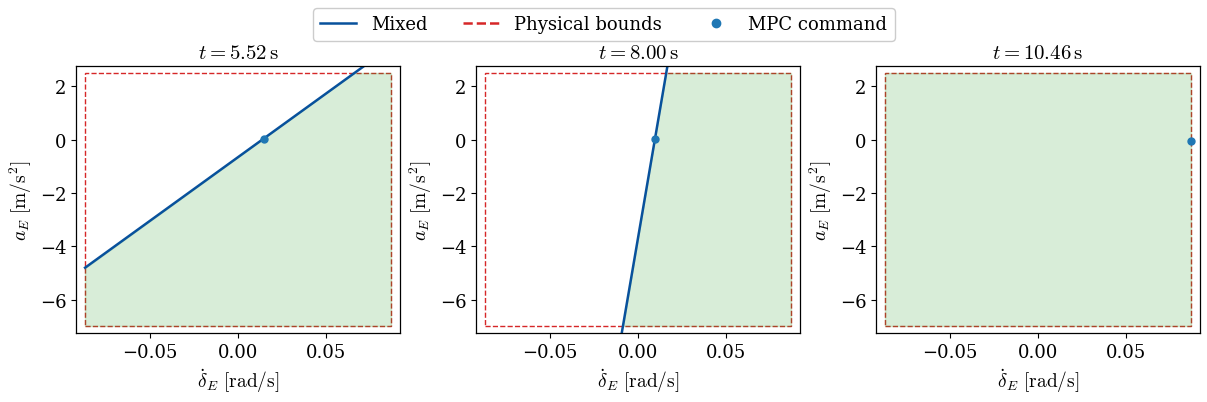

In [19]:
for run in runs:
    show(f"{run.name}_command_planes", plot_command_planes(
        run, PLANE_TIMES, stage=HJ_STAGE, softened=HJ_SOFTENED
    ))


## Figure per singola metrica (facoltative)

In [21]:
if PER_METRIC_FIGURES:
    for run in runs:
        for metric in run.metrics:
            show(f"{run.name}_{metric}_value", plot_values(run, [metric]))
            show(f"{run.name}_{metric}_limits", plot_hj_limits(
                run, metric=metric, stage=HJ_STAGE, softened=HJ_SOFTENED
            ))


## Costi dell’OCP

Costo dell’orizzonte ottimizzato a ciascun passo, non costo istantaneo del solo comando applicato.

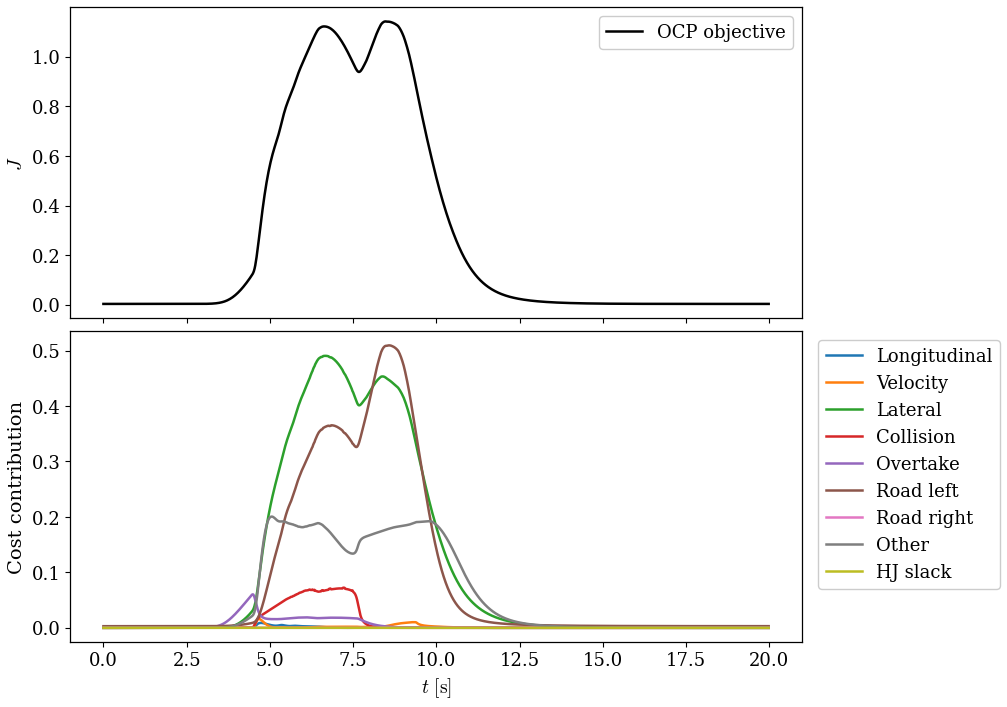

,run,max_abs_decomposition_error
0,mixed,4.286904e-07


In [23]:
for run in runs:
    show(f"{run.name}_costs", plot_costs(run))

cost_checks = pd.DataFrame([cost_consistency(run) for run in runs])
display(cost_checks)


## Tempi di calcolo

Le statistiche usano tutti i campioni salvati, incluso il primo. Gli archivi correnti registrano il solo solver OCP: questi numeri non comprendono interpolazione HJ, aggiornamento dei parametri o ciclo completo del planner. Il confronto con il periodo di controllo è quindi parziale. Eventuali timer hj_time e controller_time verranno inclusi automaticamente nella tabella quando presenti. La macchina usata per il plotting non è quella su cui vengono misurati questi tempi.

,run,timer,samples,mean_ms,median_ms,p95_ms,p99_ms,max_ms,deadline_ms,within_deadline_pct,deadline_misses
0,mixed,OCP solver,1000,93.36,9.796,216.549,409.388,421.409,20.0,53.3,467


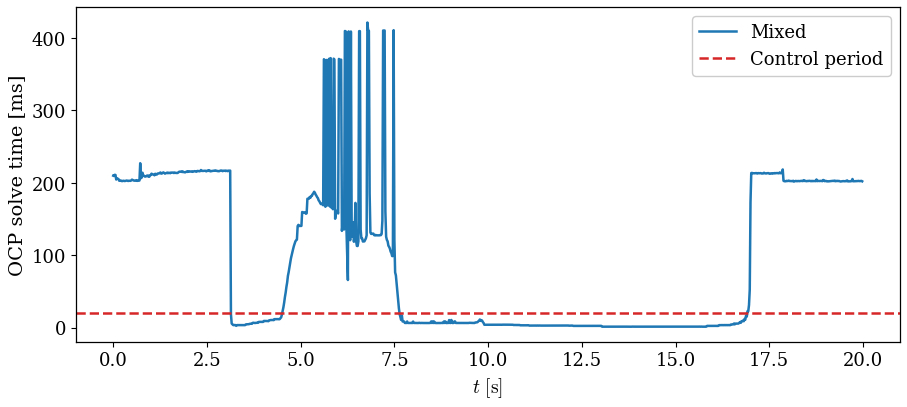

In [25]:
timing_table = timing_statistics(runs, CONTROL_FREQUENCY)
display(timing_table.round(3))
show("ocp_timings", plot_timings(runs, CONTROL_FREQUENCY))


## Esportazione

In [27]:
if EXPORT:
    exported = export_collection(
        figures, OUTPUT_GROUP, formats=FORMATS,
        tables={"timing_statistics": timing_table, "cost_consistency": cost_checks,
                "run_manifest": run_manifest(runs)},
    )
    print(f"Esportati {len(exported)} file in grafici/output/{OUTPUT_GROUP}")


Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_trajectory.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_frames.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_states.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_commands.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_values.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_hj_limits.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_command_planes.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/mixed_costs.pdf
Salvato: /workspace/scratch/5e19f9bce0e6/mpc_review/grafici/output/mixed/ocp_timings.pdf
Esportati 12 file in grafici/output/mixed
